In [1]:
import os
import re
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
DATA_DIR = "../data/" 
IMG_W, IMG_H = 128, 64     
BATCH_SIZE = 32
EPOCHS = 50
SEED = 42
IMG_EXT = {".jpg", ".jpeg", ".png",".tif",".tiff"}

In [3]:
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
def get_label(rel_path):
    """0 = gerçek (genuine), 1 = sahte (forged)."""
    name = os.path.basename(rel_path)
    low = rel_path.lower()
    base = name.lower()

    # CEDAR: original_X_Y.png / forgeries_X_Y.png
    if "forg" in low:
        return 1
    if "original" in base or "genuine" in low:
        return 0

    # BHSig260: B-S-1-G-01.jpg (G = gerçek) / H-S-1-F-01.jpg (F = sahte)
    m = re.search(r"[-_]([GF])[-_]\d+", name.upper())
    if m:
        return 0 if m.group(1) == "G" else 1

    return None

In [5]:
def get_group(rel_path):
    parts = rel_path.split(os.sep)
    folders = [f for f in parts[:-1] if get_label(f) is None]  # etiket klasörlerini at
    nums = re.findall(r"\d+", parts[-1])
    writer = nums[0] if nums else "unknown"
    return "_".join(folders + [writer])

In [6]:
def collect_files(data_dir):
    records = []
    for root, _, names in os.walk(data_dir):
        for name in names:
            if os.path.splitext(name)[1].lower() not in IMG_EXT:
                continue
            full = os.path.join(root, name)
            rel = os.path.relpath(full, data_dir)
            label = get_label(rel)
            if label is None:
                continue
            records.append((full, label, get_group(rel)))
    return records

In [7]:
def load_image(path):
    img = Image.open(path).convert("L").resize((IMG_W, IMG_H))
    arr = np.asarray(img, dtype=np.float32) / 255.0   # 0-1 normalizasyon
    return arr.T  

In [8]:
records = collect_files(DATA_DIR)
print(f"Toplam görüntü: {len(records)}")

Toplam görüntü: 16680


In [9]:
labels_all = np.array([r[1] for r in records])
print(f"Gerçek (0): {(labels_all == 0).sum()}  |  Sahte (1): {(labels_all == 1).sum()}")

Gerçek (0): 7560  |  Sahte (1): 9120


In [10]:
X = np.stack([load_image(r[0]) for r in records]).astype(np.float32)
y = labels_all.astype(np.float32)
groups = np.array([r[2] for r in records])
print(f"X shape: {X.shape}  |  Yazar grubu sayısı: {len(np.unique(groups))}")

X shape: (16680, 128, 64)  |  Yazar grubu sayısı: 316


In [11]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))


In [12]:
X_train_full, X_test = X[train_idx], X[test_idx]
y_train_full, y_test = y[train_idx], y[test_idx]
groups_train_full = groups[train_idx]

In [13]:
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, val_idx = next(gss_val.split(X_train_full, y_train_full, groups_train_full))

In [14]:
X_train, X_val = X_train_full[tr_idx], X_train_full[val_idx]
y_train, y_val = y_train_full[tr_idx], y_train_full[val_idx]

print(f"Train: {X_train.shape[0]}  |  Val: {X_val.shape[0]}  |  Test: {X_test.shape[0]}")

Train: 10578  |  Val: 2718  |  Test: 3384


In [15]:
model = keras.Sequential([
    layers.Input(shape=(IMG_W, IMG_H)),
    layers.SimpleRNN(128, return_sequences=False, dropout=0.2),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])

In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 128)                 │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,025 (129.00 KB)

 Trainable params: 33,025 (129.00 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
import collections

In [19]:
records = collect_files(DATA_DIR)
labels_all = np.array([r[1] for r in records])
print("Etiket dağılımı:", collections.Counter(labels_all.tolist()))
print("Toplam:", len(records), "(beklenen: CEDAR 2640 + BHSig 14040 = 16680)")

Etiket dağılımı: Counter({1: 9120, 0: 7560})
Toplam: 16680 (beklenen: CEDAR 2640 + BHSig 14040 = 16680)


In [20]:
skipped = []
for root, _, names in os.walk(DATA_DIR):
    for n in names:
        if os.path.splitext(n)[1].lower() in IMG_EXT:
            full = os.path.join(root, n)
            if get_label(os.path.relpath(full, DATA_DIR)) is None:
                skipped.append(os.path.relpath(full, DATA_DIR))

print("Atlanan:", len(skipped))
for s in skipped[:10]:
    print("  ", s)

Atlanan: 0


In [22]:
cw = compute_class_weight(class_weight="balanced", classes=np.array([0.0, 1.0]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

Class weights: {0: np.float64(1.101875), 1: np.float64(0.9153686396677051)}


In [23]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=8,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                      min_lr=1e-6),
    keras.callbacks.ModelCheckpoint("best_simplernn.keras", monitor="val_auc",
                                    mode="max", save_best_only=True),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 36s 89ms/step - accuracy: 0.4915 - auc: 0.4961 - loss: 0.7024 - val_accuracy: 0.4507 - val_auc: 0.5016 - val_loss: 0.6937 - learning_rate: 0.0010
Epoch 2/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 25s 77ms/step - accuracy: 0.5009 - auc: 0.4970 - loss: 0.6935 - val_accuracy: 0.4503 - val_auc: 0.5000 - val_loss: 0.6936 - learning_rate: 0.0010
Epoch 3/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 26s 80ms/step - accuracy: 0.5137 - auc: 0.4952 - loss: 0.6932 - val_accuracy: 0.4503 - val_auc: 0.5000 - val_loss: 0.6942 - learning_rate: 0.0010
Epoch 4/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 27s 81ms/step - accuracy: 0.5074 - auc: 0.4932 - loss: 0.6933 - val_accuracy: 0.4503 - val_auc: 0.5000 - val_loss: 0.6935 - learning_rate: 0.0010
Epoch 5/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.5109 - auc: 0.4961 - loss: 0.6932 - val_accuracy: 0.4503 - val_auc: 0.5000 - val_loss: 0.6934 - learning_rate: 0.0010
Epoch 6/50
331/331 ━━━━━━━━━━━━━━━━━━━━ 27s 82ms/step - accuracy: 0.49

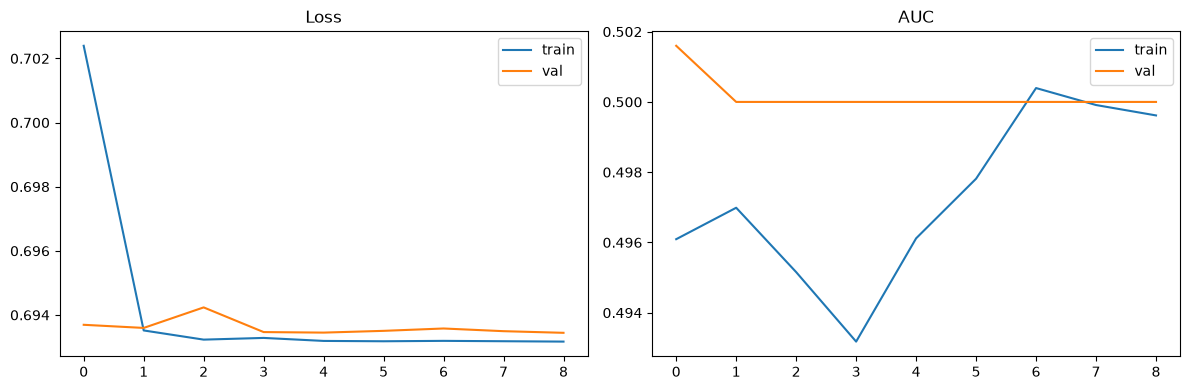

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(history.history["auc"], label="train")
axes[1].plot(history.history["val_auc"], label="val")
axes[1].set_title("AUC")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=120)
plt.show()

In [25]:
test_loss, test_acc, test_auc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}  |  Accuracy: {test_acc:.4f}  |  AUC: {test_auc:.4f}")

y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Genuine", "Forged"]))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC-AUC (sklearn): {roc_auc_score(y_test, y_prob):.4f}")



Test Loss: 0.6936  |  Accuracy: 0.4554  |  AUC: 0.5026

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.45      1.00      0.62      1536
      Forged       0.86      0.00      0.01      1848

    accuracy                           0.46      3384
   macro avg       0.66      0.50      0.32      3384
weighted avg       0.67      0.46      0.29      3384

Confusion Matrix:
[[1535    1]
 [1842    6]]

ROC-AUC (sklearn): 0.5627


In [26]:
model.save("../model/simplernn_signature.keras")